# COMP 472 | Random Forest Classification

**Fall 2026 · Kaggle Project**
**Method:** Random Forest implemented from scratch with NumPy (built on our own Decision Tree)
**Datasets:** Visual object recognition (50 classes) and sentiment analysis (3 classes)

---

### What is a Random Forest?

A Random Forest is **many decision trees that vote**. One deep tree memorizes the training data (overfitting). If we train many trees that are each a bit *different*, their mistakes are different too, and the majority vote cancels many of them out.

Each tree is made different in two ways:

1. **Bootstrap sample:** each tree trains on `n` rows drawn *with replacement* from the training set. Some rows appear twice, some not at all.
2. **Random features per split:** at every node, the tree only looks at a random subset of the features (for example √d of them) when choosing the best split.

To predict, every tree votes for a class and the class with the most votes wins.

**Sections:** 01 Data preparation · 02 Decision Tree with random features · 03 Building the forest · 04 Tuning · 05 Forest vs. single tree · 06 Error analysis · 07 Kaggle submission · 08 Reproducibility

## 01 · Data preparation

We use **exactly the same** 80/20 stratified split as the k-NN and Decision Tree notebooks (`random_state=42`), so all results can be compared fairly. Put the Kaggle CSV files in the notebook's working directory.

**Required packages:** `numpy`, `pandas`, `matplotlib`, `scikit-learn` (only for `train_test_split`).

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

SEED = 42  # one seed for the whole notebook, so every run gives the same results

image_train = pd.read_csv("image_train.csv")
sentiment_train = pd.read_csv("sentiment_train.csv")

print("Image dataset:", image_train.shape)
print("Sentiment dataset:", sentiment_train.shape)

Image dataset: (20000, 502)
Sentiment dataset: (12000, 770)


### Separate features and labels, then split

`X` holds the feature vectors, `y` holds the correct labels. The `id` column is not a feature, so we drop it.

We convert to NumPy arrays right away (`.to_numpy()`), because our tree code works on NumPy arrays. Then we delete the pandas tables with `del`: they hold a second copy of the same numbers, and a forest needs that memory more. (The split is the same rows either way: `train_test_split` only looks at the row order and the labels.)

We keep the list of feature column names, to pick the same columns from the test files later.

In [2]:
image_feature_columns = image_train.columns.drop(["id", "label"])
sentiment_feature_columns = sentiment_train.columns.drop(["id", "label"])

X_image = image_train[image_feature_columns].to_numpy()
y_image = image_train["label"].astype(int).to_numpy()

X_sentiment = sentiment_train[sentiment_feature_columns].to_numpy()
y_sentiment = sentiment_train["label"].astype(int).to_numpy()

del image_train, sentiment_train   # free memory: we only use the NumPy arrays from here on

X_img_train, X_img_val, y_img_train, y_img_val = train_test_split(
    X_image, y_image,
    test_size=0.2,
    random_state=42,
    stratify=y_image
)

X_sent_train, X_sent_val, y_sent_train, y_sent_val = train_test_split(
    X_sentiment, y_sentiment,
    test_size=0.2,
    random_state=42,
    stratify=y_sentiment
)

print("Image training:", X_img_train.shape, " validation:", X_img_val.shape)
print("Sentiment training:", X_sent_train.shape, " validation:", X_sent_val.shape)

Image training: (16000, 500)  validation: (4000, 500)
Sentiment training: (9600, 768)  validation: (2400, 768)


## 02 · Decision Tree with random features

We reuse the Decision Tree from `Decision_Tree.ipynb`. Most of the code is copied unchanged. There is **one real change**:

| | Decision Tree notebook | This notebook |
|:--|:--|:--|
| Features tried at each split | all of them (500 or 768) | a random subset of size `max_features` |

With `max_features=None` the tree tries every feature, so it behaves exactly like the original tree. We check this below.

### Impurity functions (copied unchanged)

Both take a table of class counts and return how "mixed" the group is. 0 means pure (one class only).

In [3]:
def entropy_counts(counts):
    counts = np.asarray(counts, dtype=float)
    total = counts.sum(axis=-1, keepdims=True)

    probabilities = np.divide(
        counts,
        total,
        out=np.zeros_like(counts),
        where=total > 0
    )

    return -np.sum(
        probabilities * np.log2(np.maximum(probabilities, 1e-12)),
        axis=-1
    )


def gini_counts(counts):
    counts = np.asarray(counts, dtype=float)
    total = counts.sum(axis=-1, keepdims=True)

    probabilities = np.divide(
        counts,
        total,
        out=np.zeros_like(counts),
        where=total > 0
    )

    return np.sum(
        probabilities * (1 - probabilities),
        axis=-1
    )


print("Gini, pure group [10, 0]:", gini_counts([10, 0]))
print("Gini, mixed group [5, 5]:", gini_counts([5, 5]))

Gini, pure group [10, 0]: 0.0
Gini, mixed group [5, 5]: 0.5


### How many features to try at each split?

`max_features` can be:

- `None`: all features (a normal decision tree)
- `"sqrt"`: √d, 22 of 500 image features, 27 of 768 sentiment features
- `"log2"`: log₂(d), 8 image features, 9 sentiment features
- `"third"`: d/3, about 166 image features, 256 sentiment features
- a number, e.g. `50`

In [4]:
def number_of_features_to_try(max_features, n_features):
    if max_features is None:
        k = n_features
    elif max_features == "sqrt":
        k = int(np.sqrt(n_features))
    elif max_features == "log2":
        k = int(np.log2(n_features))
    elif max_features == "third":
        k = n_features // 3
    else:
        k = int(max_features)

    return max(1, min(k, n_features))  # keep k between 1 and n_features


for option in [None, "sqrt", "log2", "third"]:
    print(f"{str(option):>6}: image {number_of_features_to_try(option, 500):>3}, "
          f"sentiment {number_of_features_to_try(option, 768):>3}")

  None: image 500, sentiment 768
  sqrt: image  22, sentiment  27
  log2: image   8, sentiment   9
 third: image 166, sentiment 256


### Best split over a given list of features

This does **the same math** as the teammate's `best_split`:

1. For each feature, take 9 candidate thresholds (the 10%, 20%, …, 90% quantiles).
2. Count how many samples of each class fall left/right of every threshold (the cumulative-count trick).
3. Gain = parent impurity − weighted impurity of the two children. Return the feature and threshold with the largest gain.

Two differences:

- It only looks at the features in `features_to_try` (the list `build_tree` gives it), not all of them. It receives `values`: just this node's samples, and just those feature columns.
- **Speed:** the teammate's version uses a Python `for` loop over the features, one at a time. This version handles **all the chosen features at once** using 2D/3D NumPy arrays (the only small loop left is over the 9 thresholds). A forest builds thousands of small nodes, and at a small node the Python loop overhead was most of the time. Measured on one image tree with d/3 features: **72 s → 8 s**, with exactly the same tree.

**How to read the array shapes** (`n` = samples at this node, `k` = features tried, `t` = 9 thresholds, `C` = classes):

| Variable | Shape | Meaning |
|:--|:--|:--|
| `values` | (n, k) | this node's samples, only the k chosen feature columns |
| `thresholds` | (t, k) | 9 quantiles for each feature |
| `bins` | (n, k) | for each sample and feature: how many thresholds the value is above (0 to 9) |
| `counts` | (k, t+1, C) | how many samples of each class are in each bin, per feature |
| `left_counts` | (k, t, C) | class counts on the left side of each threshold (cumulative sum over bins) |
| `gains` | (k, t) | the gain of every (feature, threshold) pair |

In [5]:
def best_split(values, y, features_to_try, n_thresholds=9, min_samples_leaf=5,
               criterion="gini"):
    # values: (n, k) table, column i holds feature features_to_try[i] for this node's samples
    n_samples = values.shape[0]
    n_classes = int(y.max()) + 1

    impurity_function = {
        "entropy": entropy_counts,
        "gini": gini_counts
    }[criterion]

    parent_counts = np.bincount(y, minlength=n_classes)
    parent_impurity = impurity_function(parent_counts)

    # 1. Candidate thresholds for every chosen feature at once
    features = np.asarray(features_to_try)
    k = len(features)
    thresholds = np.quantile(values, np.linspace(0.1, 0.9, n_thresholds), axis=0)  # (t, k)

    # 2. Bin number of each value = how many thresholds it is above (0 .. t)
    #    "value <= threshold j" means "bin <= j", so bins 0..j are on the left of threshold j
    bins = np.zeros(values.shape, dtype=int)                             # (n, k)
    for j in range(n_thresholds):
        bins += values > thresholds[j]       # +1 wherever the value is above threshold j

    # Count samples per (feature, bin, class) with one bincount:
    # each combination gets its own number, like a 3-digit code
    code = (np.arange(k) * (n_thresholds + 1) + bins) * n_classes + y[:, None]
    counts = np.bincount(code.ravel(), minlength=k * (n_thresholds + 1) * n_classes)
    counts = counts.reshape(k, n_thresholds + 1, n_classes)              # (k, t+1, C)

    # Left side of threshold j = bins 0..j (cumulative sum); right side = the rest
    left_counts = np.cumsum(counts, axis=1)[:, :-1, :]                   # (k, t, C)
    right_counts = parent_counts - left_counts

    n_left = left_counts.sum(axis=2)                                     # (k, t)
    n_right = n_samples - n_left

    # 3. Gain of every (feature, threshold) pair
    gains = (
        parent_impurity
        - (n_left / n_samples) * impurity_function(left_counts)
        - (n_right / n_samples) * impurity_function(right_counts)
    )

    valid = (n_left >= min_samples_leaf) & (n_right >= min_samples_leaf)
    gains[~valid] = -np.inf

    # Best pair: argmax over the whole (k, t) table, turned back into (row, column)
    f, t = np.unravel_index(np.argmax(gains), gains.shape)

    if not gains[f, t] > 0:          # no split improves impurity
        return None, None, 0

    return int(features[f]), thresholds[t, f], float(gains[f, t])

### Build the tree

Same recursive tree as before, with three changes:

- **`rows` instead of copies:** the teammate's tree makes a copy of the data for each child (`X[left_mask]`, with all 500 or 768 columns). A forest builds thousands of nodes, and these copies used too much memory on our laptops. Here the full `X` is never copied: each node only keeps the **row numbers** (`rows`) of its samples, and copies just the few columns it tests (`X[np.ix_(rows, features_to_try)]` = "these rows, these columns"). The resulting tree is exactly the same.
- **`max_features`**: at every node we draw a **new** random set of features with `rng.choice(..., replace=False)` (no feature picked twice). Different nodes look at different features.
- **`rng`**: a NumPy random generator. Giving each tree its own generator with a fixed seed makes the whole forest reproducible.

`max_depth=None` means "no depth limit": the tree only stops because of `min_samples_split`, `min_samples_leaf` or a pure node.

In [6]:
def build_tree(X, y, depth=0, max_depth=6,
               min_samples_leaf=5, min_samples_split=20,
               criterion="gini", max_features=None, rng=None, rows=None):

    if rows is None:
        rows = np.arange(len(y))       # the root node holds every row

    y_node = y[rows]                   # labels of the samples in this node
    majority_class = np.bincount(y_node).argmax()

    if (
        (max_depth is not None and depth >= max_depth)
        or len(np.unique(y_node)) == 1
        or len(y_node) < min_samples_split
        or len(y_node) < 2 * min_samples_leaf
    ):
        return {"label": majority_class}

    # Pick which features this node is allowed to look at
    n_features = X.shape[1]
    k = number_of_features_to_try(max_features, n_features)

    if k == n_features:
        features_to_try = np.arange(n_features)        # normal decision tree
    else:
        features_to_try = rng.choice(n_features, size=k, replace=False)

    values = X[np.ix_(rows, features_to_try)]          # this node's rows, chosen columns only

    feature, threshold, gain = best_split(
        values, y_node, features_to_try,
        min_samples_leaf=min_samples_leaf,
        criterion=criterion
    )

    if feature is None or gain <= 0:
        return {"label": majority_class}

    goes_left = X[rows, feature] <= threshold

    settings = dict(max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                    min_samples_split=min_samples_split, criterion=criterion,
                    max_features=max_features, rng=rng)

    return {
        "feature": feature,
        "threshold": threshold,
        "left": build_tree(X, y, depth + 1, rows=rows[goes_left], **settings),
        "right": build_tree(X, y, depth + 1, rows=rows[~goes_left], **settings)
    }

### Predict with one tree (copied unchanged)

For each sample, follow the `feature <= threshold` tests from the root down to a leaf, and return the leaf's label.

In [7]:
def predict_one(tree, x):
    if "label" in tree:
        return tree["label"]

    if x[tree["feature"]] <= tree["threshold"]:
        return predict_one(tree["left"], x)
    else:
        return predict_one(tree["right"], x)


def predict_tree(tree, X):
    return np.array([predict_one(tree, x) for x in X])


def accuracy(predictions, y):
    return np.mean(predictions == y) * 100

### Check 1: with all features, we get the teammate's tree back

The best sentiment tree in `Decision_Tree.ipynb` (Gini, depth 6, leaf 50, split 20) scored **55.2% train / 49.79% validation**. With `max_features=None`, our modified code should give the same numbers. This proves we did not break anything.

In [8]:
start = time.time()

check_tree = build_tree(
    X_sent_train, y_sent_train,
    max_depth=6, min_samples_leaf=50, min_samples_split=20,
    criterion="gini", max_features=None
)

print(f"Train accuracy:      {accuracy(predict_tree(check_tree, X_sent_train), y_sent_train):.2f}%")
print(f"Validation accuracy: {accuracy(predict_tree(check_tree, X_sent_val), y_sent_val):.2f}%")
print(f"Time: {time.time() - start:.1f} s")

Train accuracy:      55.21%
Validation accuracy: 49.79%
Time: 2.6 s


### Check 2: one tree with √d random features — how fast is it?

A forest needs many trees, so the time per tree matters. Here we time **one** tree on the full training split for each task, with all features vs. √d features.

(Accuracy of a single random-feature tree is usually *lower* than a normal tree: each split is chosen from fewer options. The forest's vote is what makes up for it.)

In [9]:
timing_results = []

for task, X_tr, y_tr, X_va, y_va, depth in [
    ("Image",     X_img_train,  y_img_train,  X_img_val,  y_img_val,  14),
    ("Sentiment", X_sent_train, y_sent_train, X_sent_val, y_sent_val, 6),
]:
    for max_features in [None, "sqrt"]:
        rng = np.random.default_rng(SEED)
        start = time.time()

        tree = build_tree(X_tr, y_tr, max_depth=depth,
                          min_samples_leaf=5, min_samples_split=20,
                          criterion="gini", max_features=max_features, rng=rng)

        elapsed = time.time() - start

        timing_results.append({
            "Task": task,
            "Max depth": depth,
            "Max features": str(max_features),
            "Train acc (%)": accuracy(predict_tree(tree, X_tr), y_tr),
            "Val acc (%)": accuracy(predict_tree(tree, X_va), y_va),
            "Time (s)": elapsed
        })
        print(f"{task}, max_features={max_features}: {elapsed:.1f} s")

timing_df = pd.DataFrame(timing_results).round(2)
timing_df

Image, max_features=None: 7.4 s


Image, max_features=sqrt: 0.4 s


Sentiment, max_features=None: 2.6 s
Sentiment, max_features=sqrt: 0.1 s


,Task,Max depth,Max features,Train acc (%),Val acc (%),Time (s)
0,Image,14,None,19.36,10.82,7.39
1,Image,14,sqrt,16.28,7.70,0.35
2,Sentiment,6,None,55.43,49.46,2.58
3,Sentiment,6,sqrt,51.78,46.58,0.09


## 03 · Building the forest

The forest is built in three small pieces:

1. **Bootstrap:** give each tree its own random copy of the training rows.
2. **Train many trees:** each tree uses its own bootstrap sample and its own random features at every split.
3. **Majority vote:** every tree predicts a class, and the most common answer wins.

### Step A · Bootstrap sample

From `n` training rows we draw `n` row numbers **with replacement**: after a row is picked, it goes back in the "bag" and can be picked again. So some rows appear 2–3 times and some are not picked at all.

On average a bootstrap sample contains only about **63%** of the different rows (the math: the chance a row is never picked is (1 − 1/n)ⁿ ≈ 1/e ≈ 37%). This is what makes each tree see a slightly different dataset.

The small example below draws 10 row numbers out of 10.

In [10]:
def bootstrap_sample(X, y, rng):
    n_samples = X.shape[0]
    rows = rng.integers(0, n_samples, size=n_samples)  # n random row numbers, repeats allowed
    return X[rows], y[rows]


# Small example with 10 rows
rng = np.random.default_rng(SEED)
rows = rng.integers(0, 10, size=10)
print("Rows picked:     ", sorted(rows.tolist()))
print("Different rows:  ", len(np.unique(rows)), "out of 10")

# On the real image training set
rng = np.random.default_rng(SEED)
X_boot, y_boot = bootstrap_sample(X_img_train, y_img_train, rng)
unique_rows = len(np.unique(X_boot, axis=0))
print(f"Image bootstrap: {len(X_boot)} rows, {unique_rows} different "
      f"({unique_rows / len(X_boot) * 100:.1f}%)")

Rows picked:      [0, 0, 0, 2, 4, 4, 6, 6, 7, 8]
Different rows:   6 out of 10


Image bootstrap: 16000 rows, 10172 different (63.6%)


### Step B · Train many trees

`build_forest` repeats the same two lines `n_trees` times: make a bootstrap sample, then build a tree on it with random features.

**Reproducibility:** tree number `i` gets its own random generator `np.random.default_rng(seed + i)`. Tree 0 uses seed 42, tree 1 uses seed 43, and so on. Running the notebook again gives exactly the same forest.

The forest is simply a Python **list of trees**.

In [11]:
def build_forest(X, y, n_trees=10, max_depth=None, max_features="sqrt",
                 min_samples_leaf=5, min_samples_split=20,
                 criterion="gini", seed=SEED, verbose=False):
    forest = []

    for i in range(n_trees):
        rng = np.random.default_rng(seed + i)       # different, but fixed, randomness per tree

        X_boot, y_boot = bootstrap_sample(X, y, rng)

        tree = build_tree(
            X_boot, y_boot,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            min_samples_split=min_samples_split,
            criterion=criterion,
            max_features=max_features,
            rng=rng
        )
        forest.append(tree)

        if verbose and (i + 1) % 10 == 0:
            print(f"  {i + 1} trees built")

    return forest

### Step C · Majority vote

1. `all_tree_predictions` asks every tree for its predictions. The result is a table with **one row per tree** and **one column per sample**.
2. `majority_vote` looks at each column (one sample) and picks the class that appears most often. `np.bincount` counts how many votes each class got, and `argmax` picks the class with the most votes. If two classes tie, `argmax` picks the smaller class number.

We keep these as two functions because it lets us compute "accuracy with the first 1, 2, 3, … trees" later **without retraining anything**: we just vote with the first rows of the table.

In [12]:
def all_tree_predictions(forest, X):
    # shape: (number of trees, number of samples)
    return np.array([predict_tree(tree, X) for tree in forest])


def majority_vote(tree_predictions):
    n_samples = tree_predictions.shape[1]
    return np.array([
        np.bincount(tree_predictions[:, j]).argmax()   # most common class in column j
        for j in range(n_samples)
    ])


def predict_forest(forest, X):
    return majority_vote(all_tree_predictions(forest, X))


# Small example: 3 trees, 4 samples
example_votes = np.array([
    [0, 1, 2, 1],   # tree 1
    [0, 2, 2, 0],   # tree 2
    [1, 1, 2, 2],   # tree 3
])
print("Majority vote:", majority_vote(example_votes))   # expected [0 1 2 0] (last one is a 3-way tie -> smallest class)

Majority vote: [0 1 2 0]


### First forest: 25 trees vs. one tree

A first test with the **same settings as the best single trees** from `Decision_Tree.ipynb`, so the only difference is "one tree" vs. "a forest of 25 random trees":

| Task | Max depth | Min leaf | Min split | Max features |
|:--|--:|--:|--:|:--|
| Image | 14 | 5 | 20 | √d |
| Sentiment | 6 | 50 | 20 | √d |

We tune these settings properly in the next section.

In [13]:
first_settings = {
    "Image":     dict(max_depth=14, min_samples_leaf=5,  min_samples_split=20),
    "Sentiment": dict(max_depth=6,  min_samples_leaf=50, min_samples_split=20),
}
single_tree_val = {"Image": 10.82, "Sentiment": 49.79}   # best single trees (Decision_Tree.ipynb)

datasets = {
    "Image":     (X_img_train,  y_img_train,  X_img_val,  y_img_val),
    "Sentiment": (X_sent_train, y_sent_train, X_sent_val, y_sent_val),
}

first_forest_results = []
val_accuracy_by_trees = {}   # task -> list of validation accuracies using the first 1, 2, ..., 25 trees

for task, (X_tr, y_tr, X_va, y_va) in datasets.items():
    print(task)
    start = time.time()
    forest = build_forest(X_tr, y_tr, n_trees=25, max_features="sqrt",
                          criterion="gini", verbose=True, **first_settings[task])
    train_time = time.time() - start

    train_votes = all_tree_predictions(forest, X_tr)
    val_votes = all_tree_predictions(forest, X_va)

    val_accuracy_by_trees[task] = [
        accuracy(majority_vote(val_votes[:k]), y_va) for k in range(1, len(forest) + 1)
    ]

    first_forest_results.append({
        "Task": task,
        "Model": "Random Forest (25 trees)",
        "Train acc (%)": accuracy(majority_vote(train_votes), y_tr),
        "Val acc (%)": accuracy(majority_vote(val_votes), y_va),
        "Train time (s)": train_time,
    })
    print(f"  done in {train_time:.1f} s\n")

first_forest_df = pd.DataFrame(first_forest_results).round(2)
first_forest_df

Image


  10 trees built


  20 trees built


  done in 9.2 s

Sentiment


  10 trees built


  20 trees built


  done in 2.7 s



,Task,Model,Train acc (%),Val acc (%),Train time (s)
0,Image,Random Forest (25 trees),42.59,15.08,9.16
1,Sentiment,Random Forest (25 trees),64.08,55.42,2.68


### Does adding trees help?

Each point uses only the **first k trees** of the forest above. The dashed line is the best single Decision Tree.

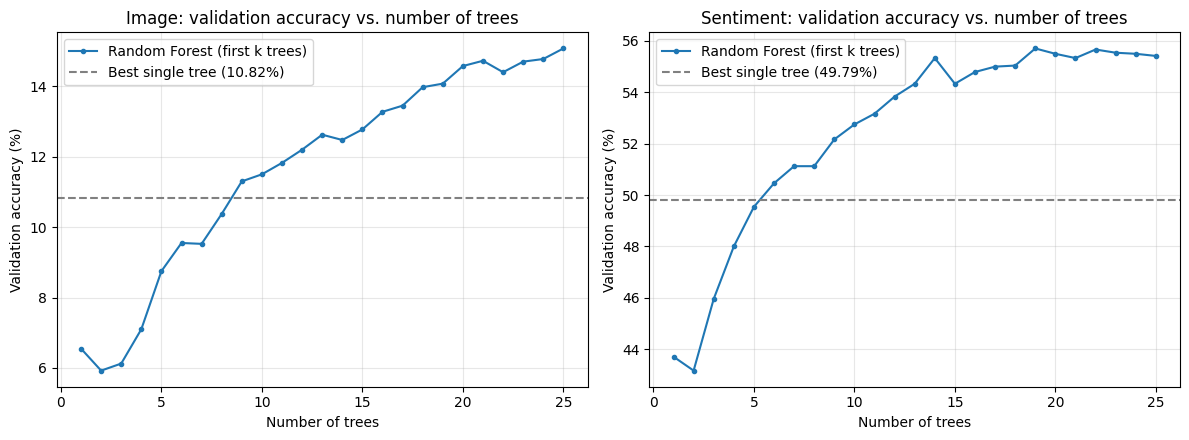

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, task in zip(axes, ["Image", "Sentiment"]):
    n_trees = range(1, len(val_accuracy_by_trees[task]) + 1)
    ax.plot(n_trees, val_accuracy_by_trees[task], marker="o", markersize=3,
            label="Random Forest (first k trees)")
    ax.axhline(single_tree_val[task], color="gray", linestyle="--",
               label=f"Best single tree ({single_tree_val[task]}%)")
    ax.set_title(f"{task}: validation accuracy vs. number of trees")
    ax.set_xlabel("Number of trees")
    ax.set_ylabel("Validation accuracy (%)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

**Observations (first forest):**

- With 25 trees the forest **beats the best single tree on both tasks**: image 15.08% vs. 10.82%, sentiment 55.42% vs. 49.79%, with the same depth and leaf settings.
- With only 1–4 trees the forest is *worse* than one normal tree. Each random tree is weaker on its own, so the vote needs enough trees before it helps.
- **Image** accuracy is still rising at 25 trees, so more trees should help. **Sentiment** levels off at about 55.5% after roughly 15–20 trees.
- The image forest still shows a big train/validation gap (42.6% vs. 15.1%), so it is still overfitting. The next section tunes depth and features per split.

## 04 · Tuning the forest

There are three main settings to tune:

| Setting | What it controls | Values tried |
|:--|:--|:--|
| `max_depth` | how deep each tree can grow | Image: 10, 14, 20, None · Sentiment: 6, 10, 14, None |
| `max_features` | how many random features each split looks at | √d, log₂(d), d/3 |
| `n_trees` | how many trees vote | 10, 25, 50, 100 |

Trying every combination would take hours, so we tune **one setting at a time** and keep the best value before moving on:

1. **Depth**, with 25 trees and √d features.
2. **Features per split**, with 25 trees and the best depth from step 1.
3. **Number of trees**, with the best depth and features: we train one forest of 100 trees and vote with the first 10, 25, 50 and 100 trees.

The best value is always chosen by **validation accuracy**, never training accuracy.

**Settings kept fixed:** `min_samples_leaf=5`, `min_samples_split=20`, Gini impurity, 9 candidate thresholds per feature, and bootstrap samples of size n. These are the "other parameters" of our implementation. We did not tune them, because each extra setting multiplies the running time and the three settings above are the ones that define a Random Forest. The Decision Tree notebook already compared Gini vs. entropy and the leaf/split sizes for a single tree.

### A helper to run one experiment

`evaluate_forest` trains one forest and returns a row for the results table. It also returns the tree-by-tree prediction tables, so the "number of trees" experiment can reuse them.

The **gap** column is train accuracy − validation accuracy. A big gap means the model memorizes the training data (overfitting).

In [15]:
all_results = []   # every experiment row goes here; saved to CSV at the end


def evaluate_forest(task, experiment, n_trees, max_depth, max_features,
                    min_samples_leaf=5, min_samples_split=20):
    X_tr, y_tr, X_va, y_va = datasets[task]

    start = time.time()
    forest = build_forest(X_tr, y_tr, n_trees=n_trees, max_depth=max_depth,
                          max_features=max_features,
                          min_samples_leaf=min_samples_leaf,
                          min_samples_split=min_samples_split,
                          criterion="gini", seed=SEED)
    train_time = time.time() - start

    train_votes = all_tree_predictions(forest, X_tr)
    val_votes = all_tree_predictions(forest, X_va)

    train_acc = accuracy(majority_vote(train_votes), y_tr)
    val_acc = accuracy(majority_vote(val_votes), y_va)

    row = {
        "Experiment": experiment,
        "Task": task,
        "Trees": n_trees,
        "Max depth": max_depth,
        "Max features": max_features,
        "Min leaf": min_samples_leaf,
        "Train acc (%)": round(train_acc, 2),
        "Val acc (%)": round(val_acc, 2),
        "Gap": round(train_acc - val_acc, 2),
        "Train time (s)": round(train_time, 1),
    }
    print(f"{task:9} | trees={n_trees:3} depth={str(max_depth):4} features={max_features:5} | "
          f"train {train_acc:5.2f}%  val {val_acc:5.2f}%  ({train_time:.0f} s)")

    return row, train_votes, val_votes


def results_table(rows):
    # pandas would turn depths [10, None] into [10.0, NaN]; showing them as text keeps "10" and "None"
    table = pd.DataFrame(rows)
    table["Max depth"] = [str(r["Max depth"]) for r in rows]
    return table

### Step 1 · Maximum depth (25 trees, √d features)

In [16]:
depths_to_try = {
    "Image":     [10, 14, 20, None],
    "Sentiment": [6, 10, 14, None],
}

depth_rows = []
for task, depths in depths_to_try.items():
    for depth in depths:
        row, _, _ = evaluate_forest(task, "1 depth", n_trees=25,
                                    max_depth=depth, max_features="sqrt")
        depth_rows.append(row)

all_results += depth_rows

best_depth = {}
for task in depths_to_try:
    task_rows = [r for r in depth_rows if r["Task"] == task]
    best_depth[task] = max(task_rows, key=lambda r: r["Val acc (%)"])["Max depth"]

print("\nBest depth:", best_depth)
results_table(depth_rows)

Image     | trees= 25 depth=10   features=sqrt  | train 24.68%  val 13.28%  (6 s)


Image     | trees= 25 depth=14   features=sqrt  | train 42.59%  val 15.07%  (9 s)


Image     | trees= 25 depth=20   features=sqrt  | train 65.74%  val 15.50%  (14 s)


Image     | trees= 25 depth=None features=sqrt  | train 86.09%  val 16.50%  (19 s)


Sentiment | trees= 25 depth=6    features=sqrt  | train 65.25%  val 56.42%  (3 s)


Sentiment | trees= 25 depth=10   features=sqrt  | train 88.89%  val 55.62%  (6 s)


Sentiment | trees= 25 depth=14   features=sqrt  | train 95.62%  val 56.58%  (8 s)


Sentiment | trees= 25 depth=None features=sqrt  | train 96.05%  val 54.29%  (8 s)

Best depth: {'Image': None, 'Sentiment': 14}


,Experiment,Task,Trees,Max depth,Max features,Min leaf,Train acc (%),Val acc (%),Gap,Train time (s)
0,1 depth,Image,25,10,sqrt,5,24.68,13.28,11.41,5.9
1,1 depth,Image,25,14,sqrt,5,42.59,15.08,27.52,9.2
2,1 depth,Image,25,20,sqrt,5,65.74,15.50,50.24,13.6
3,1 depth,Image,25,None,sqrt,5,86.09,16.50,69.59,18.7
4,1 depth,Sentiment,25,6,sqrt,5,65.25,56.42,8.83,2.8
5,1 depth,Sentiment,25,10,sqrt,5,88.89,55.62,33.26,5.9
6,1 depth,Sentiment,25,14,sqrt,5,95.62,56.58,39.04,7.9
7,1 depth,Sentiment,25,None,sqrt,5,96.05,54.29,41.76,8.2


**Training vs. validation accuracy by depth.** If training accuracy keeps climbing while validation stays flat or drops, deeper trees are overfitting.

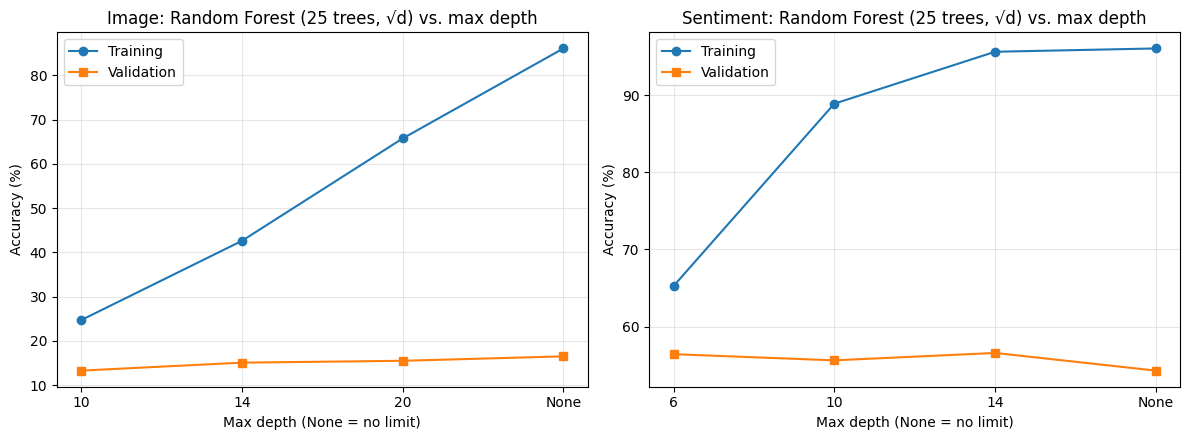

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, task in zip(axes, depths_to_try):
    task_rows = [r for r in depth_rows if r["Task"] == task]
    labels = [str(r["Max depth"]) for r in task_rows]
    ax.plot(labels, [r["Train acc (%)"] for r in task_rows], marker="o", label="Training")
    ax.plot(labels, [r["Val acc (%)"] for r in task_rows], marker="s", label="Validation")
    ax.set_title(f"{task}: Random Forest (25 trees, √d) vs. max depth")
    ax.set_xlabel("Max depth (None = no limit)")
    ax.set_ylabel("Accuracy (%)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

**Observations (depth):**

- **Image:** training accuracy climbs from 24.7% (depth 10) to 86.1% (no limit), and validation accuracy *also* rises a little, from 13.3% to 16.5%. A single tree got worse when it grew too deep; the forest does not, because the vote averages away much of what each deep tree memorized. Best: **no depth limit**.
- **Sentiment:** training accuracy goes from 65% to 96%, but validation stays flat around 54–57%. Depth 6 (56.42%) and depth 14 (56.58%) are almost tied; with no limit, validation drops to 54.29%, which is a sign of overfitting. We keep **depth 14** because it scored highest, but the difference to depth 6 is small (0.16 points) and could be noise.

### Step 2 · Features per split (25 trees, best depth)

The √d row is already done in step 1, so we only train the log₂(d) and d/3 forests here.

- **Fewer features** (log₂): trees are more different from each other, but each tree is weaker.
- **More features** (d/3): each tree is stronger, but the trees look more alike, so the vote helps less. It is also much slower.

In [18]:
feature_rows = []
for task in depths_to_try:
    # reuse the sqrt result from step 1
    sqrt_row = [r for r in depth_rows
                if r["Task"] == task and r["Max depth"] == best_depth[task]][0]
    feature_rows.append({**sqrt_row, "Experiment": "2 features"})

    for max_features in ["log2", "third"]:
        row, _, _ = evaluate_forest(task, "2 features", n_trees=25,
                                    max_depth=best_depth[task], max_features=max_features)
        feature_rows.append(row)

all_results += [r for r in feature_rows if r["Max features"] != "sqrt"]

best_features = {}
for task in depths_to_try:
    task_rows = [r for r in feature_rows if r["Task"] == task]
    best_features[task] = max(task_rows, key=lambda r: r["Val acc (%)"])["Max features"]

print("\nBest max_features:", best_features)
results_table(feature_rows)

Image     | trees= 25 depth=None features=log2  | train 79.05%  val 13.93%  (12 s)


Image     | trees= 25 depth=None features=third | train 90.10%  val 17.97%  (104 s)


Sentiment | trees= 25 depth=14   features=log2  | train 94.27%  val 51.96%  (8 s)


Sentiment | trees= 25 depth=14   features=third | train 97.57%  val 57.38%  (75 s)

Best max_features: {'Image': 'third', 'Sentiment': 'third'}


,Experiment,Task,Trees,Max depth,Max features,Min leaf,Train acc (%),Val acc (%),Gap,Train time (s)
0,2 features,Image,25,None,sqrt,5,86.09,16.50,69.59,18.7
1,2 features,Image,25,None,log2,5,79.05,13.92,65.12,12.0
2,2 features,Image,25,None,third,5,90.10,17.97,72.13,103.7
3,2 features,Sentiment,25,14,sqrt,5,95.62,56.58,39.04,7.9
4,2 features,Sentiment,25,14,log2,5,94.27,51.96,42.31,8.5
5,2 features,Sentiment,25,14,third,5,97.57,57.38,40.20,74.8


**Observations (features per split):**

- **d/3 is the best on both tasks**: image 17.97% (vs. 16.50% with √d), sentiment 57.38% (vs. 56.58%).
- **log₂(d) is the worst** (image 13.92%, sentiment 51.96%). With only 8–9 features per split, each tree is too weak, and the vote cannot make up for it.
- The price of d/3 is time: each forest took about 4–9 times longer than with √d (image 105 s vs. 23 s for 25 trees).

### Step 3 · Number of trees (best depth and features)

We train **one** forest of 100 trees per task. Because every tree is trained independently, the first 10 trees of this forest are exactly a 10-tree forest. So we can read off the 10, 25, 50 and 100-tree results by voting with the first k trees, without training four separate forests.

In [19]:
tree_counts = [10, 25, 50, 100]
tree_rows = []
val_curve = {}               # task -> validation accuracy using the first 1..100 trees
best_val_predictions = {}    # task -> validation predictions of the full 100-tree forest (used in section 06)

for task in depths_to_try:
    X_tr, y_tr, X_va, y_va = datasets[task]
    row, train_votes, val_votes = evaluate_forest(
        task, "3 trees", n_trees=100,
        max_depth=best_depth[task], max_features=best_features[task]
    )

    val_curve[task] = [accuracy(majority_vote(val_votes[:k]), y_va) for k in range(1, 101)]
    best_val_predictions[task] = majority_vote(val_votes)

    for k in tree_counts:
        train_acc = accuracy(majority_vote(train_votes[:k]), y_tr)
        val_acc = accuracy(majority_vote(val_votes[:k]), y_va)
        tree_rows.append({
            **row,
            "Trees": k,
            "Train acc (%)": round(train_acc, 2),
            "Val acc (%)": round(val_acc, 2),
            "Gap": round(train_acc - val_acc, 2),
            "Train time (s)": round(row["Train time (s)"] * k / 100, 1),  # about k/100 of the full time
        })

all_results += tree_rows
results_table(tree_rows)

Image     | trees=100 depth=None features=third | train 98.06%  val 23.85%  (625 s)


Sentiment | trees=100 depth=14   features=third | train 99.47%  val 59.71%  (170 s)


,Experiment,Task,Trees,Max depth,Max features,Min leaf,Train acc (%),Val acc (%),Gap,Train time (s)
0,3 trees,Image,10,None,third,5,69.89,14.00,55.89,62.5
1,3 trees,Image,25,None,third,5,90.10,17.97,72.13,156.2
2,3 trees,Image,50,None,third,5,96.59,21.40,75.19,312.5
3,3 trees,Image,100,None,third,5,98.06,23.85,74.21,625.0
4,3 trees,Sentiment,10,14,third,5,91.99,53.33,38.66,17.0
5,3 trees,Sentiment,25,14,third,5,97.57,57.38,40.20,42.5
6,3 trees,Sentiment,50,14,third,5,98.88,58.50,40.38,84.9
7,3 trees,Sentiment,100,14,third,5,99.47,59.71,39.76,169.8


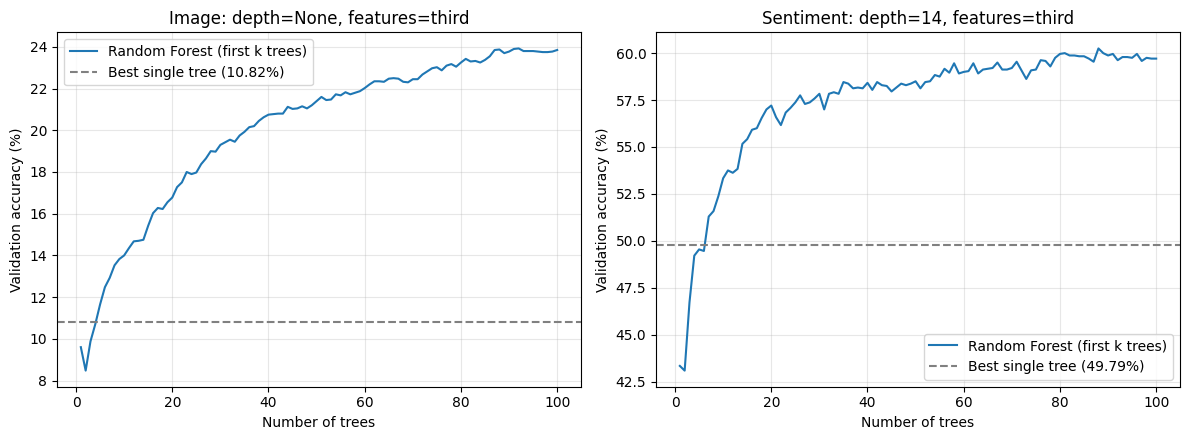

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, task in zip(axes, depths_to_try):
    ax.plot(range(1, 101), val_curve[task], label="Random Forest (first k trees)")
    ax.axhline(single_tree_val[task], color="gray", linestyle="--",
               label=f"Best single tree ({single_tree_val[task]}%)")
    ax.set_title(f"{task}: depth={best_depth[task]}, features={best_features[task]}")
    ax.set_xlabel("Number of trees")
    ax.set_ylabel("Validation accuracy (%)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

**Observations (number of trees):**

| Trees | Image val (%) | Sentiment val (%) |
|--:|--:|--:|
| 10 | 14.00 | 53.33 |
| 25 | 17.97 | 57.38 |
| 50 | 21.40 | 58.50 |
| 100 | **23.85** | **59.71** |

- **More trees always helped.** Sentiment levels off after about 80 trees. Image is still slowly rising at 100 trees, so more trees could help a little more, but each image tree costs about 7 s.
- **Adding trees does not cause overfitting.** Training accuracy is near 100% (98–99.5%), because every tree is grown very deep, yet validation accuracy keeps going up as trees are added. Each new tree only adds one more vote; it cannot make the forest memorize more.

### Save all tuning results

Every experiment row is saved to `random_forest_results.csv`, like the other notebooks do.

In [21]:
results_df = results_table(all_results)
results_df.to_csv("random_forest_results.csv", index=False)

print("Saved", len(results_df), "rows to random_forest_results.csv")
results_df

Saved 20 rows to random_forest_results.csv


,Experiment,Task,Trees,Max depth,Max features,Min leaf,Train acc (%),Val acc (%),Gap,Train time (s)
0,1 depth,Image,25,10,sqrt,5,24.68,13.28,11.41,5.9
1,1 depth,Image,25,14,sqrt,5,42.59,15.08,27.52,9.2
2,1 depth,Image,25,20,sqrt,5,65.74,15.50,50.24,13.6
3,1 depth,Image,25,None,sqrt,5,86.09,16.50,69.59,18.7
4,1 depth,Sentiment,25,6,sqrt,5,65.25,56.42,8.83,2.8
5,1 depth,Sentiment,25,10,sqrt,5,88.89,55.62,33.26,5.9
6,1 depth,Sentiment,25,14,sqrt,5,95.62,56.58,39.04,7.9
7,1 depth,Sentiment,25,None,sqrt,5,96.05,54.29,41.76,8.2
8,2 features,Image,25,None,log2,5,79.05,13.92,65.12,12.0
9,2 features,Image,25,None,third,5,90.10,17.97,72.13,103.7


## 05 · Random Forest vs. single Decision Tree

Validation accuracy on the same split for all models (single tree and k-NN numbers from the teammates' notebooks):

| Task | Model | Settings | Train acc (%) | Val acc (%) |
|:--|:--|:--|--:|--:|
| Image | Decision Tree | Gini, depth 14, leaf 5 | 19.4 | 10.82 |
| Image | **Random Forest** | 100 trees, no depth limit, d/3 features | 98.06 | **23.85** |
| Image | k-NN | k = 1 | – | 53.08 |
| Sentiment | Decision Tree | Gini, depth 6, leaf 50 | 55.2 | 49.79 |
| Sentiment | **Random Forest** | 100 trees, depth 14, d/3 features | 99.47 | **59.71** |
| Sentiment | k-NN | k = 20 | – | 57.46 |

**Does the forest reduce overfitting?**

- The forest is **much better than one tree on unseen data**: image 23.85% vs. 10.82% (more than double), sentiment 59.71% vs. 49.79% (+10 points).
- The train/validation **gap is bigger** for the forest, because its trees are grown much deeper (training ≈ 98–99%). So the forest does not stop the trees from memorizing the training data.
- What the forest reduces is the **damage** from overfitting. A single sentiment tree got *worse* on validation when it grew deeper (48% at depth 6 → 45% at depth 14). The forest's validation accuracy stays the same or improves with deeper trees, and keeps improving as trees are added. Each tree makes different mistakes (different bootstrap rows, different features), and the majority vote cancels many of them out.

**Compared with k-NN:**

- **Sentiment:** the Random Forest (59.71%) is our **best sentiment model so far**, ahead of k-NN with k = 20 (57.46%).
- **Image:** the forest (23.85%) is still far behind k-NN (53.08%). A likely reason: each tree split looks at **one feature at a time** (`feature <= threshold`), while k-NN compares all 500 numbers together through a distance. With 50 classes and only 320 training examples per class, single-feature splits seem to be a poor fit for these image features.

## 06 · Error analysis

Accuracy tells us *how often* the forest is wrong, not *where*. Here we look at the mistakes of the **best forests from step 3** (100 trees, best depth and features) on the **validation split**.

A **confusion matrix** is a table where row = true class, column = predicted class. The diagonal holds the correct predictions; everything off the diagonal is a mistake. We use `confusion_matrix` from scikit-learn, which is allowed (it is a metric, not a model).

Two words we use per class:

- **Recall** = of all examples that *really are* class X, how many did we predict as X? (correct ÷ row total)
- **Precision** = of all examples we *predicted* as X, how many really are X? (correct ÷ column total)

### Sentiment: is Neutral harder than Negative or Positive?

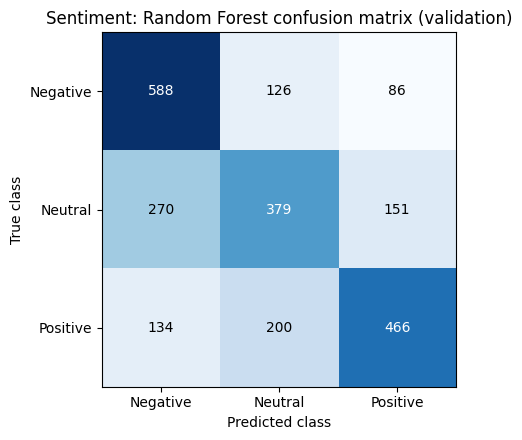

,Class,Validation examples,Predicted as this class,Recall (%),Precision (%)
0,Negative,800,992,73.50,59.27
1,Neutral,800,705,47.38,53.76
2,Positive,800,703,58.25,66.29


In [22]:
from sklearn.metrics import confusion_matrix

sentiment_names = ["Negative", "Neutral", "Positive"]
sent_cm = confusion_matrix(y_sent_val, best_val_predictions["Sentiment"], labels=[0, 1, 2])

sentiment_class_table = pd.DataFrame({
    "Class": sentiment_names,
    "Validation examples": sent_cm.sum(axis=1),
    "Predicted as this class": sent_cm.sum(axis=0),
    "Recall (%)": (sent_cm.diagonal() / sent_cm.sum(axis=1) * 100).round(2),
    "Precision (%)": (sent_cm.diagonal() / sent_cm.sum(axis=0) * 100).round(2),
})

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(sent_cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, sent_cm[i, j], ha="center", va="center",
                color="white" if sent_cm[i, j] > sent_cm.max() / 2 else "black")
ax.set_xticks(range(3), sentiment_names)
ax.set_yticks(range(3), sentiment_names)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Sentiment: Random Forest confusion matrix (validation)")
plt.tight_layout()
plt.show()

sentiment_class_table

**Observations (sentiment):**

- **Yes, Neutral is the hardest class.** The forest finds only 47.38% of the true Neutral examples (recall), compared with 73.50% for Negative and 58.25% for Positive.
- **Neutral is mostly confused with Negative:** 270 of the 800 Neutral examples are predicted Negative, and 151 are predicted Positive.
- **Negative and Positive are rarely confused with each other** (86 and 134 mistakes), much less often than either one is confused with Neutral. Neutral sits "in between" the two other classes, so most mistakes happen at its borders.
- **The forest predicts Negative too often:** 992 predictions for only 800 real Negative examples. That is why Negative has the highest recall (73.50%) but a lower precision (59.27%): many of the examples it calls Negative are really Neutral or Positive.

### Image: which classes are hardest, and which ones get mixed up?

The validation split has 80 examples of each of the 50 classes. We do not know the object names, only the class numbers.

In [23]:
img_cm = confusion_matrix(y_img_val, best_val_predictions["Image"], labels=range(50))

image_class_table = pd.DataFrame({
    "Class": range(50),
    "Recall (%)": (img_cm.diagonal() / img_cm.sum(axis=1) * 100).round(2),
}).sort_values("Recall (%)").reset_index(drop=True)

print("5 hardest classes:")
print(image_class_table.head(5).to_string(index=False))
print()
print("5 easiest classes:")
print(image_class_table.tail(5).to_string(index=False))

# Most frequent mistakes: the largest numbers off the diagonal
mistakes = img_cm.copy()
np.fill_diagonal(mistakes, 0)                          # ignore correct predictions
largest = np.argsort(mistakes, axis=None)[::-1][:10]   # positions of the 10 largest counts
true_cls, pred_cls = np.unravel_index(largest, mistakes.shape)

confused_pairs = pd.DataFrame({
    "True class": true_cls,
    "Predicted as": pred_cls,
    "Count (of 80)": mistakes[true_cls, pred_cls],
})
print()
print("10 most frequent mistakes:")
print(confused_pairs.to_string(index=False))

5 hardest classes:
 Class  Recall (%)
    21        5.00
    22        5.00
    29        6.25
    24        7.50
    41        7.50

5 easiest classes:
 Class  Recall (%)
    48       47.50
    12       47.50
     5       56.25
     2       60.00
    46       70.00

10 most frequent mistakes:
 True class  Predicted as  Count (of 80)
          4             2             14
          3             2             13
         38            25             10
         44             8             10
         27            25             10
         25            12              9
          6             7              9
         14            11              9
         37            39              9
         17            47              8


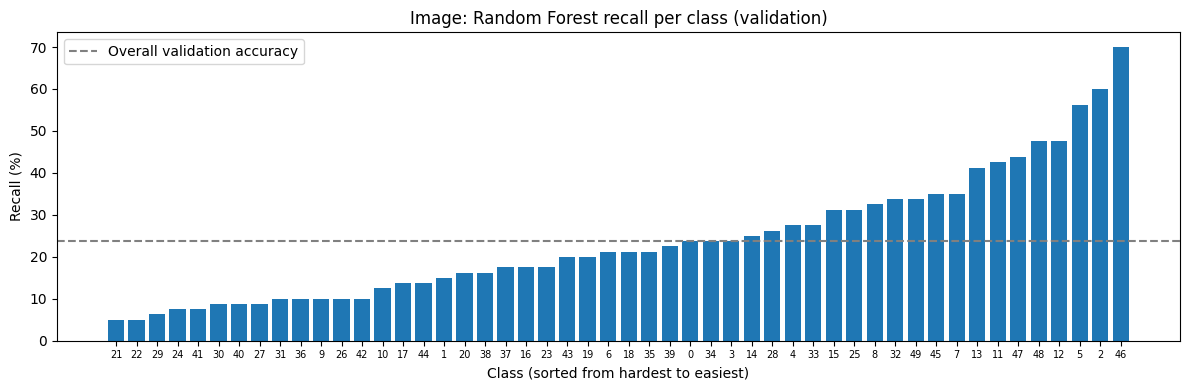

In [24]:
plt.figure(figsize=(12, 4))
plt.bar(range(50), image_class_table["Recall (%)"])
plt.xticks(range(50), image_class_table["Class"], fontsize=7)
plt.axhline(accuracy(best_val_predictions["Image"], y_img_val), color="gray", linestyle="--",
            label="Overall validation accuracy")
plt.xlabel("Class (sorted from hardest to easiest)")
plt.ylabel("Recall (%)")
plt.title("Image: Random Forest recall per class (validation)")
plt.legend()
plt.tight_layout()
plt.show()

**Observations (image):**

- **Accuracy varies a lot between classes:** from 5% (classes 21 and 22, only 4 of 80 correct) to 70% (class 46). More than half of the classes are below the overall accuracy of 23.85%; a few easy classes pull the average up.
- **The mistakes are spread out.** Even the most frequent mistake (class 4 predicted as class 2) happens only 14 times out of 80. Most wrong predictions are scattered over many different classes, not concentrated in a few pairs.
- **Some classes attract wrong predictions:** class 2 is the wrong answer for both class 4 (14 times) and class 3 (13 times), and class 25 for both class 38 and class 27 (10 times each). Class 2 is also one of the easiest classes (60% recall), probably partly because the forest predicts it often.
- We only have class numbers, not object names, so we cannot check whether the confused classes are visually similar objects.

## 07 · Kaggle submission

The validation split was only used to **choose the settings**. For the final model we retrain on **all labeled rows** (train + validation = 20,000 image rows and 12,000 sentiment rows), because more training data usually gives a slightly better model.

Final settings, taken from section 04:

| Task | Trees | Max depth | Max features | Min leaf | Min split | Criterion |
|:--|--:|--:|:--|--:|--:|:--|
| Image | 100 | None | d/3 | 5 | 20 | Gini |
| Sentiment | 100 | 14 | d/3 | 5 | 20 | Gini |

Training both forests takes about 20 minutes.

The file is saved as **`submission_random_forest.csv`**, a different name than the k-NN notebook's `submission.csv`, so neither notebook overwrites the other's file. Like the other notebooks, the predictions are matched to `sample_submission.csv` **by id, not by row order**.

In [11]:
final_settings = {
    "Image":     dict(n_trees=100, max_depth=None, max_features="third"),
    "Sentiment": dict(n_trees=100, max_depth=14,   max_features="third"),
}

final_forests = {}
for task, X_all, y_all in [("Image", X_image, y_image),
                           ("Sentiment", X_sentiment, y_sentiment)]:
    print(f"{task}: training on {len(y_all)} rows")
    start = time.time()
    final_forests[task] = build_forest(
        X_all, y_all,
        min_samples_leaf=5, min_samples_split=20, criterion="gini",
        seed=SEED, verbose=True, **final_settings[task]
    )
    print(f"  done in {time.time() - start:.0f} s\n")

Image: training on 20000 rows


  10 trees built


  20 trees built


  30 trees built


  40 trees built


  50 trees built


... (11 outputs left out)

  70 trees built


  80 trees built


  90 trees built


  100 trees built
  done in 5478 s



### Predict the test sets and build the submission file

In [12]:
image_test = pd.read_csv("image_test.csv")
sentiment_test = pd.read_csv("sentiment_test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

# Use the same feature columns, in the same order, as in training
image_predictions = predict_forest(
    final_forests["Image"], image_test[image_feature_columns].to_numpy()
)
sentiment_predictions = predict_forest(
    final_forests["Sentiment"], sentiment_test[sentiment_feature_columns].to_numpy()
)

predictions = pd.concat([
    pd.DataFrame({"id": image_test["id"], "label": image_predictions}),
    pd.DataFrame({"id": sentiment_test["id"], "label": sentiment_predictions})
], ignore_index=True)

# Put the predictions in the same order as sample_submission.csv, matching by id
submission = sample_submission[["id"]].merge(
    predictions, on="id", how="left", validate="one_to_one"
)

# Safety checks before saving
assert len(submission) == 10000
assert submission["id"].is_unique
assert submission["label"].notna().all()

submission["label"] = submission["label"].astype(int)

image_rows = submission["id"].str.startswith("img_")
sentiment_rows = submission["id"].str.startswith("text_")

assert image_rows.sum() == 5000
assert sentiment_rows.sum() == 5000
assert submission.loc[image_rows, "label"].between(0, 49).all()
assert submission.loc[sentiment_rows, "label"].between(0, 2).all()

submission.to_csv("submission_random_forest.csv", index=False)

print("Saved submission_random_forest.csv with", len(submission), "predictions")
print("Different image classes predicted:", submission.loc[image_rows, "label"].nunique(), "of 50")
print("Sentiment predictions per class (0 = Neg, 1 = Neutral, 2 = Pos):",
      submission.loc[sentiment_rows, "label"].value_counts().sort_index().to_dict())
submission.head()

Saved submission_random_forest.csv with 10000 predictions
Different image classes predicted: 50 of 50
Sentiment predictions per class (0 = Neg, 1 = Neutral, 2 = Pos): {0: 2534, 1: 1341, 2: 1125}


,id,label
0,text_003234,2
1,text_004517,1
2,img_000140,26
3,img_004880,11
4,text_002494,0


## 08 · Reproducibility

- **Random seed:** `SEED = 42`. The train/validation split uses `random_state=42`, and tree number `i` in a forest uses `np.random.default_rng(SEED + i)`, both for its bootstrap sample and for its random features. Running the notebook again gives the same accuracies.
- **Training procedure:** 80/20 stratified split → tune on the validation split (section 04) → retrain on all labeled rows with the chosen settings → predict the test sets (section 07).
- **Final hyperparameters:** see the table in section 07.
- **Running time** on a regular laptop CPU: section 04 takes about 25 minutes and section 07 about 15–20 minutes (one run of section 07 was much slower, probably because the laptop went to sleep).
- **Library versions** used for the saved outputs are printed below.

In [25]:
import sys
import matplotlib
import sklearn

print("Python:      ", sys.version.split()[0])
print("NumPy:       ", np.__version__)
print("pandas:      ", pd.__version__)
print("Matplotlib:  ", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__, "(only train_test_split and confusion_matrix are used)")
print("Seed:        ", SEED)

Python:       3.13.5
NumPy:        2.3.0
pandas:       2.3.3
Matplotlib:   3.10.3
scikit-learn: 1.9.1 (only train_test_split and confusion_matrix are used)
Seed:         42
